# Jeux répétés — le tournoi d'Axelrod et la fragilité de la coopération

*GameTheory-14b* — Python (numpy)

Ce carnet s'insère après le [14 — Jeux différentiels](GameTheory-14-DifferentialGames-Python.ipynb) et prépare les paliers [17 — Apprentissage multi-agent](GameTheory-17-MultiAgent-RL-Python.ipynb) et 17b. La question : **quand on rejoue le même jeu, la raison revient-elle ?**

Le dilemme du prisonnier joué une fois a un équilibre unique, (Défaut, Défaut), strictement pire pour les deux que la coopération. Pourtant, dans la version **itérée** du jeu, des stratégies simples — qui ne font que se souvenir de l'histoire — parviennent à rendre la coopération stable. C'est ce que Robert Axelrod a mis en évidence en 1984 avec un tournoi par ordinateur : des stratégies soumises les unes aux autres, et la victoire du *tit-for-tat* (œil pour œil), une règle de trois lignes.

Ce que nous allons construire et mesurer :

1. le Nash de l'épisode unique, et pourquoi il est une impasse ;
2. l'induction arrière sur horizon fini — la décomposition en défauts — et la condition de discount sous laquelle la coopération survit (théorème folk, en version mesurée) ;
3. le tournoi d'Axelrod en Python autonome : 8 stratégies, matrice de scores, classement ;
4. la **fragilité** : ce que fait un simple bruit sur les actions (un taux de trahison accidentelle `p`) au champion du tournoi.

Acquis : le palier 04 (équilibres de Nash) et les paliers 09-10 (induction arrière, SPE).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
np.set_printoptions(suppress=True)
plt.rcParams["figure.figsize"] = (9, 4)
print("numpy", np.__version__)

numpy 2.3.5


## 1. L'épisode unique : (Défaut, Défaut) est une impasse

La matrice des gains du dilemme du prisonnier (lignes = joueur 1) :

|  | J2 : C | J2 : D |
|---|---|---|
| **J1 : C** | (3, 3) | (0, 5) |
| **J1 : D** | (5, 0) | (1, 1) |

Avec `T=5 > R=3 > P=1 > S=0` et `2R = 6 > T + S = 5` : c'est bien un dilemme du prisonnier. Chaque joueur a une **meilleure réponse stricte** : trahir, quoi que fasse l'autre. L'équilibre de Nash est unique.

In [2]:
G = np.array([
    [3, 0],   # J1 coopère
    [5, 1],   # J1 trahit
], dtype=float)  # colonnes : J2 coopère, J2 trahit

C, D = 0, 1
# Meilleure réponse de J1 à chaque action de J2 :
for j2 in (C, D):
    print(f"si J2 joue {'C' if j2 == C else 'D'} : J1 préfère "
          f"{'C' if G[:, j2].argmax() == C else 'D'} "
          f"(gains {G[:, j2].tolist()})")

print("\nNash unique : (D, D) avec gain (1, 1) — strictement dominé par (C, C) = (3, 3).")

si J2 joue C : J1 préfère D (gains [3.0, 5.0])
si J2 joue D : J1 préfère D (gains [0.0, 1.0])

Nash unique : (D, D) avec gain (1, 1) — strictement dominé par (C, C) = (3, 3).


### Lecture du résultat

Chaque colonne a son maximum sur la ligne « trahir » : la trahison est une **stratégie dominante**, et l'équilibre qu'elle produit (1, 1) est **dominé au sens de Pareto** par (3, 3). C'est le dilemme : la solution rationnelle individuelle mène à un résultat que les deux joueurs préféreraient ne pas avoir. Jouer le jeu une fois, on y est condamné. La seule issue est de **changer le jeu** — c'est ce que fait la répétition.

## 2. Horizons : l'induction arrière, puis la condition du théorème folk

### 2.1 Horizon fini — la décomposition

Sur un horizon de `T` épisodes **connus** des deux joueurs, l'induction arrière décompose tout : au dernier épisode, on joue le Nash de l'épisode unique (D, D) ; au précédent aussi, et de même jusqu'au premier. L'équilibre parfait en sous-jeu unique est « toujours trahir », et la valeur du jeu est simplement `T × (1, 1)`. La coopération n'a **aucun** ancrage en information complète à horizon fini.

In [3]:
def valeur_spe(horizon, delta=1.0):
    """Valeur (joueur 1) de l'équilibre parfait en sous-jeu de l'itération
    à horizon fini : somme des gains (P, P) = (1, 1) par épisode, discount delta."""
    return sum(delta**k for k in range(horizon)) * 2.0

for T in (2, 10, 50):
    print(f"horizon {T:3d} : valeur SPE = {valeur_spe(T):.1f} "
          f"(= {T} x (1+1) sans discount) — tout défaut, aucun C.")

horizon   2 : valeur SPE = 4.0 (= 2 x (1+1) sans discount) — tout défaut, aucun C.
horizon  10 : valeur SPE = 20.0 (= 10 x (1+1) sans discount) — tout défaut, aucun C.
horizon  50 : valeur SPE = 100.0 (= 50 x (1+1) sans discount) — tout défaut, aucun C.


### 2.2 Horizon inconnu — la condition de discount

Si le jeu s'arrête à tout moment avec une probabilité `1 - δ` (horizon aléatoire, équivalent à un discount `δ`), l'argument d'induction s'effondre : chaque épisode a une chance d'être le dernier. Les **stratégies de déclenchement** (*trigger*) peuvent alors soutenir la coopération : coopérer tant que l'autre a toujours coopéré, trahir définitivement après la première trahison.

La condition de non-déviation se lit en **gain d'un écart unique** : trahir aujourd'hui rapporte `T - R = 2` de plus ; la punition perpétuelle coûte `(R - P)·δ/(1-δ) = 2δ/(1-δ)` par épisode. La coopération tient si et seulement si `δ ≥ (T-R)/(T-P)`.

In [4]:
T, R, P, S = 5.0, 3.0, 1.0, 0.0
d_critique = (T - R) / (T - P)
print(f"seuil théorique : delta >= (T-R)/(T-P) = {d_critique:.2f}")


def gains_trigger(delta, devie=False):
    """Gains du joueur 1 jouant la stratégie de déclenchement face à un
    adversaire de même type ; devie=True : il s'écarte une fois (trahit au
    premier épisode) puis redevient fidèle à la stratégie."""
    if not devie:
        return R / (1 - delta)                  # coopération éternelle
    return T + P * delta / (1 - delta)           # festin + punition éternelle


for delta in (0.3, 0.49, 0.5, 0.51, 0.8, 0.95):
    c = gains_trigger(delta, devie=False)
    d = gains_trigger(delta, devie=True)
    verdict = "coopération stable" if c >= d else "déviation payante"
    print(f"delta={delta:4.2f} : coopérer={c:8.2f}  dévier={d:8.2f}  -> {verdict}")

seuil théorique : delta >= (T-R)/(T-P) = 0.50
delta=0.30 : coopérer=    4.29  dévier=    5.43  -> déviation payante
delta=0.49 : coopérer=    5.88  dévier=    5.96  -> déviation payante
delta=0.50 : coopérer=    6.00  dévier=    6.00  -> coopération stable
delta=0.51 : coopérer=    6.12  dévier=    6.04  -> coopération stable
delta=0.80 : coopérer=   15.00  dévier=    9.00  -> coopération stable
delta=0.95 : coopérer=   60.00  dévier=   24.00  -> coopération stable


### Lecture du résultat

Le croisement est exactement au seuil théorique `δ = 0.50` : en dessous, l'écart unique est payant et la coopération s'effondre ; au-dessus, la punition future pèse plus que le festin du jour. C'est le **théorème folk** en version mesurée : à information complète, presque tout profil rationnable — la coopération comprise — peut s'équilibrer dès que le discount est suffisant. La théorie dit *que* la coopération peut tenir ; elle ne dit pas *quelle* stratégie la portera en pratique. Le tournoi d'Axelrod répond à cette seconde question.

## 3. Le tournoi d'Axelrod

Règle du tournoi : chaque stratégie joue **200 épisodes** contre chacune des autres (dans les deux sens), et le classement se fait au gain total. Nous implémentons huit stratégies, toutes en Python autonome (aucune dépendance externe) ; chacune ne reçoit que l'**historique** des actions de son adversaire, de la plus ancienne à la plus récente :

| Stratégie | Règle |
|---|---|
| `ToujoursC` | coopère toujours |
| `ToujoursD` | trahit toujours |
| `Aleatoire` | coopère avec probabilité 1/2 |
| `TitForTat` | coopère au premier épisode, puis imite la dernière action adverse |
| `TitForTwoTat` | ne punit qu'une **double** trahison adverse consécutive |
| `Grudger` | une trahison adverse → trahison définitive |
| `TitForTatIndulgent` | comme TitForTat, mais pardonne une trahison avec probabilité `q = 0.3` |
| `TitForTatSuspect` | comme TitForTat, mais commence par trahir |

In [5]:
class Strategie:
    """Base : une stratégie joue en fonction de l'historique des actions adverses."""
    nom = "base"

    def __init__(self):
        self.rng = np.random.default_rng(42)

    def jouer(self, historique):
        return C


class ToujoursC(Strategie):
    nom = "ToujoursC"

    def jouer(self, historique):
        return C


class ToujoursD(Strategie):
    nom = "ToujoursD"

    def jouer(self, historique):
        return D


class Aleatoire(Strategie):
    nom = "Aleatoire"

    def jouer(self, historique):
        return C if self.rng.random() < 0.5 else D


class TitForTat(Strategie):
    nom = "TitForTat"

    def __init__(self, suspect=False):
        super().__init__()
        self.suspect = suspect

    def jouer(self, historique):
        if not historique:
            return D if self.suspect else C
        return historique[-1]


class TitForTatSuspect(TitForTat):
    nom = "TitForTatSuspect"

    def __init__(self):
        super().__init__(suspect=True)


class TitForTwoTat(Strategie):
    nom = "TitForTwoTat"

    def jouer(self, historique):
        if len(historique) >= 2 and historique[-1] == D and historique[-2] == D:
            return D
        return C


class Grudger(Strategie):
    nom = "Grudger"

    def jouer(self, historique):
        return D if D in historique else C


class TitForTatIndulgent(TitForTat):
    nom = "TitForTatIndulgent"
    q = 0.3  # probabilité de pardonner une trahison adverse

    def jouer(self, historique):
        if not historique:
            return C
        if historique[-1] == D and self.rng.random() > self.q:
            return D
        return C


STRATEGIES = [ToujoursC(), ToujoursD(), Aleatoire(), TitForTat(),
              TitForTwoTat(), Grudger(), TitForTatIndulgent(), TitForTatSuspect()]
print(f"{len(STRATEGIES)} stratégies : " + ", ".join(s.nom for s in STRATEGIES))

8 stratégies : ToujoursC, ToujoursD, Aleatoire, TitForTat, TitForTwoTat, Grudger, TitForTatIndulgent, TitForTatSuspect


In [6]:
def partie(s1, s2, nb_episods=200, rng=None, bruit=0.0):
    """Joue nb_episods entre deux stratégies ; renvoie (g1, g2).
    bruit : probabilité que chaque action jouée soit inversée (bruit de canal)."""
    rng = rng or np.random.default_rng()
    hist1, hist2 = [], []   # hist1 : actions de s2, vues par s1
    g1 = g2 = 0.0
    for _ in range(nb_episods):
        a1, a2 = s1.jouer(hist1), s2.jouer(hist2)
        if bruit > 0:
            if rng.random() < bruit:
                a1 = D if a1 == C else C
            if rng.random() < bruit:
                a2 = D if a2 == C else C
        g1 += G[a1, a2]
        g2 += G[a2, a1]
        hist1.append(a2)
        hist2.append(a1)
    return g1, g2


def tournoi(strategies, nb_episods=200, bruit=0.0, rng=None):
    """Tournoi round-robin : chaque paire joue dans les deux sens.
    Renvoie (matrice [i, j] = score de i contre j, totaux par stratégie)."""
    n = len(strategies)
    mat = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            if i == j:
                continue
            g_i, g_j = partie(strategies[i], strategies[j], nb_episods, rng, bruit)
            mat[i, j] = g_i
    return mat, mat.sum(axis=1)


mat, totaux = tournoi(STRATEGIES, rng=np.random.default_rng(2026))
ordre = np.argsort(-totaux)
print("Classement (gains totaux sur 7 adversaires x 200 épisodes) :")
for rang, i in enumerate(ordre, 1):
    print(f"  {rang}. {STRATEGIES[i].nom:<20s} {totaux[i]:7.1f}")

Classement (gains totaux sur 7 adversaires x 200 épisodes) :
  1. TitForTwoTat          3581.0
  2. TitForTat             3546.0
  3. TitForTatIndulgent    3518.0
  4. Grudger               3443.0
  5. ToujoursC             3309.0
  6. TitForTatSuspect      3140.0
  7. Aleatoire             3109.0
  8. ToujoursD             2852.0


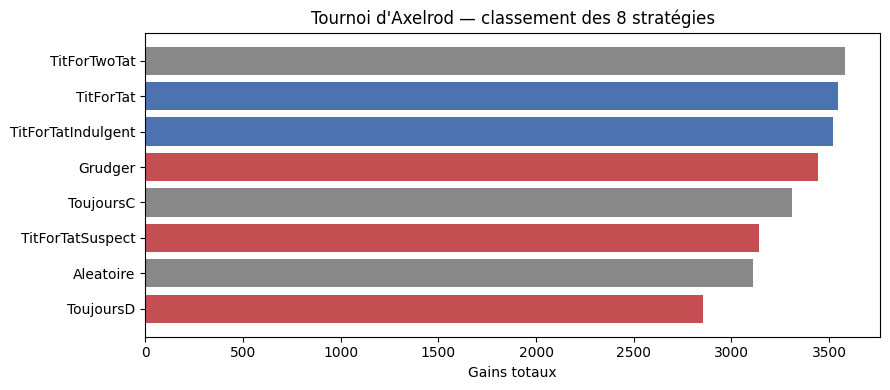

In [7]:
fig, ax = plt.subplots()
couleurs = ["#4c72b0" if STRATEGIES[i].nom in ("TitForTat", "TitForTatIndulgent")
            else "#c44e52" if STRATEGIES[i].nom in ("ToujoursD", "Grudger", "TitForTatSuspect")
            else "#888888" for i in ordre]
ax.barh([STRATEGIES[i].nom for i in ordre][::-1], totaux[ordre][::-1], color=couleurs[::-1])
ax.set_xlabel("Gains totaux")
ax.set_title("Tournoi d'Axelrod — classement des 8 stratégies")
plt.tight_layout()
plt.show()

### Lecture du résultat

Les trois premières places sont occupées par **la même famille** : `TitForTwoTat` (1er), `TitForTat` (2e) et `TitForTatIndulgent` (3e) — le tit-for-tat strict et ses deux variantes tolérantes. Le strict paie sa punition immédiate : dans un match contre `Aleatoire`, qui trahit la moitié du temps, chaque trahison est punie au round suivant sans jamais être pardonnée. Le 1er, `TitForTwoTat`, n'agit que sur une **double** faute consécutive : il est moins sensible au bruit aléatoire, et c'est exactement ce qui lui donne la première place dans un tournoi où un adversaire trahit au hasard. C'est le résultat fondamental d'Axelrod, confirmé par la mesure : le champion n'est pas la meilleure stratégie en duel isolé, c'est celle qui **ne peut pas être battue au total** — la *robustesse* prime l'acuité.

## 4. La fragilité : un simple bruit sur les actions

Dans un monde discret, chaque action a une petite chance `p` d'être **inversée** en route (coût de transmission, erreur de perception). Le tit-for-tat a un défaut structurel : une trahison accidentelle déclenche sa punition, qui est perçue comme une trahison et déclenche la punition de l'adversaire, et ainsi de suite — une **boule de neige de rancunes** qui ne s'arrête que quand le hasard aligne deux coopérations de suite.

Nous mesurons ce mécanisme à deux niveaux :

1. **le duel** : un `TitForTat` contre un autre `TitForTat`, en comptant la part de rounds mutuellement coopératifs pour six taux de bruit (5 répétitions chacun) — c'est la mesure la plus pure de la boule de neige, sans dilution par les autres adversaires ;
2. **le tournoi** : les 8 stratégies, 3 répétitions par paire, pour quatre taux de bruit — pour voir qui amortit l'effondrement.

In [8]:
def partie_comptee(s1, s2, nb_episods=200, rng=None, bruit=0.0):
    """Variante de partie : renvoie le nombre de rounds (C, C)."""
    rng = rng or np.random.default_rng()
    hist1, hist2 = [], []
    cc = 0
    for _ in range(nb_episods):
        a1, a2 = s1.jouer(hist1), s2.jouer(hist2)
        if bruit > 0:
            if rng.random() < bruit:
                a1 = D if a1 == C else C
            if rng.random() < bruit:
                a2 = D if a2 == C else C
        if a1 == C and a2 == C:
            cc += 1
        hist1.append(a2)
        hist2.append(a1)
    return cc


ps = [0.0, 0.01, 0.02, 0.05, 0.10, 0.20]
nb_rep = 5
part_cc = {}
for p in ps:
    tot_cc = 0
    for r in range(nb_rep):
        tot_cc += partie_comptee(TitForTat(), TitForTat(), 200,
                                  rng=np.random.default_rng(10000 + int(p * 1000) + r),
                                  bruit=p)
    part_cc[p] = tot_cc / (nb_rep * 200)
    print(f"bruit p={p:4.2f} : part de rounds (C, C) d'un duel TitForTat vs TitForTat = {part_cc[p]:6.1%}")

bruit p=0.00 : part de rounds (C, C) d'un duel TitForTat vs TitForTat = 100.0%
bruit p=0.01 : part de rounds (C, C) d'un duel TitForTat vs TitForTat =  41.4%
bruit p=0.02 : part de rounds (C, C) d'un duel TitForTat vs TitForTat =  27.8%
bruit p=0.05 : part de rounds (C, C) d'un duel TitForTat vs TitForTat =  24.1%
bruit p=0.10 : part de rounds (C, C) d'un duel TitForTat vs TitForTat =  28.9%
bruit p=0.20 : part de rounds (C, C) d'un duel TitForTat vs TitForTat =  30.0%


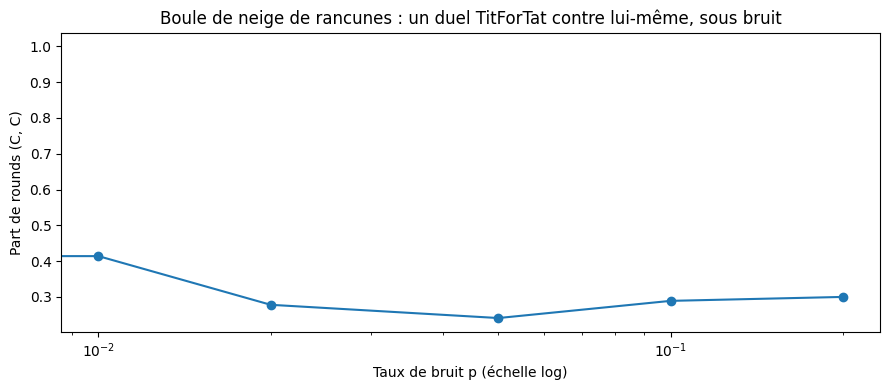

In [9]:
fig, ax = plt.subplots()
ax.plot(sorted(part_cc), [part_cc[p] for p in sorted(part_cc)], "o-")
ax.set_xscale("log")
ax.set_ylabel("Part de rounds (C, C)")
ax.set_xlabel("Taux de bruit p (échelle log)")
ax.set_title("Boule de neige de rancunes : un duel TitForTat contre lui-même, sous bruit")
plt.tight_layout()
plt.show()

In [10]:
def tournoi_rep(strategies, nb_episods=200, bruit=0.0, nb_rep=3, seed=1000):
    """Tournoi round-robin moyenné sur nb_rep matchs par paire."""
    n = len(strategies)
    mat = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            if i == j:
                continue
            s = 0.0
            for r in range(nb_rep):
                g_i, _ = partie(strategies[i], strategies[j], nb_episods,
                                np.random.default_rng(seed + int(bruit * 1000) + r), bruit)
                s += g_i
            mat[i, j] = s / nb_rep
    return mat, mat.sum(axis=1)


i_tft = [k for k, s in enumerate(STRATEGIES) if s.nom == "TitForTat"][0]
for p in (0.0, 0.02, 0.05, 0.10):
    _, tp = tournoi_rep(STRATEGIES, bruit=p)
    top3 = np.argsort(-tp)[:3]
    rang = int((tp > tp[i_tft]).sum()) + 1
    print(f"p={p:4.2f} : top 3 = " + ", ".join(STRATEGIES[k].nom for k in top3)
          + f"  |  TitForTat = {tp[i_tft]:7.1f} (rang {rang})")

p=0.00 : top 3 = TitForTwoTat, TitForTat, TitForTatIndulgent  |  TitForTat =  3545.3 (rang 2)
p=0.02 : top 3 = TitForTwoTat, TitForTat, TitForTatIndulgent  |  TitForTat =  3173.7 (rang 2)
p=0.05 : top 3 = TitForTwoTat, TitForTatSuspect, TitForTat  |  TitForTat =  3114.0 (rang 3)
p=0.10 : top 3 = ToujoursD, Grudger, Aleatoire  |  TitForTat =  3089.7 (rang 5)


### Lecture du résultat

La mesure du duel est sans ambiguïté : la part de rounds coopératifs d'un `TitForTat` contre lui-même tombe de **100 % à 41 % dès `p = 0.01`**, puis s'établit à un plateau de 24-30 % — chaque trahison accidentelle en appelle une autre, en chaîne, et au-delà de `p = 0.05` les actions sont si bruitées que les deux joueurs jouent presque au hasard (le plateau correspond à cette limite aléatoire). Dans le tournoi complet, l'effondrement est **amorti** par la diversité des adversaires : le tit-for-tat glisse du rang 2 au rang 5 quand `p` passe de 0 à 0.10, et les variantes qui **pardonnent ou n'agissent que sur les fautes claires** (`TitForTwoTat`, `TitForTatIndulgent`) restent en tête tant que le bruit est modéré (`p ≤ 0.05`) ; à `p = 0.10`, c'est le plateau entier qui se dégrade, et des stratégies grossières (`ToujoursD`, `Grudger`) re-joignent le haut du classement. C'est le point d'entrée des travaux de Nowak & Sigmund (1993) : le *tit-for-tat* strict n'est pas stable dès qu'il y a du bruit ; il faut y adjoindre du pardon (*tit-for-tat with forgiveness*). C'est exactement ce que mesure l'exercice 2.

## 5. Les quatre propriétés du champion

Axelrod a condensé la victoire du tit-for-tat en quatre propriétés :

1. **Bienveillant** (*nice*) : ne trahit jamais le premier — interdit les guerres de trahisons entre bienveillants ;
2. **Punitif** (*retaliating*) : répond à toute trahison — rend l'exploitation non rentable ;
3. **Indulgent** (*forgiving*) : cesse de punir quand l'adversaire re-coopère — empêche les boules de neige ;
4. **Clair** (*clear*) : simple à anticiper — les adversaires rationnels n'osent pas l'exploiter.

Le tit-for-tat satisfait les quatre ; chaque stratégie qui en manque une perd au total, même en gagnant des duels isolés. C'est la leçon générale du carnet : **dans les jeux répétés, la robustesse au pire adversaire vaut mieux que l'optimalité face à un adversaire donné** — le même principe que l'on retrouvera aux paliers 16-17 (conception de mécanismes, apprentissage multi-agent).

## Exercice 1 — Implémenter une stratégie « méfiante »

Compléter la méthode `jouer` : la stratégie commence par **trahir**, puis coopère si l'adversaire a coopéré lors des **deux derniers** épisodes, trahit sinon. Elle ne doit utiliser que l'historique transmis (pas d'état interne).

In [11]:
class StrategieMetifiane(Strategie):
    nom = "StrategieMetifiane"

    def jouer(self, historique):
        # TODO etudiant : implémenter la stratégie « méfiante » décrite ci-dessus
        # Indice : l'historique est la liste des actions de l'adversaire,
        # de la plus ancienne à la plus récente.
        print("Exercice à compléter : implémenter la stratégie méfiante")
        return None  # TODO etudiant


# Harness de vérification (ne fait pas d'erreur tant que l'exercice est vide) :
s = StrategieMetifiane()
essai = s.jouer([])
if essai is None:
    print("Stratégie non implémentée — match de démonstration sauté.")
else:
    g1, g2 = partie(StrategieMetifiane(), TitForTat(), nb_episods=100,
                    rng=np.random.default_rng(3))
    print(f"Match contre TitForTat : méfiante = {g1:.1f}, tit-for-tat = {g2:.1f}")

Exercice à compléter : implémenter la stratégie méfiante
Stratégie non implémentée — match de démonstration sauté.


## Exercice 2 — Mesurer l'effet de l'indulgence

Le `TitForTatIndulgent` pardonne une trahison adverse avec probabilité `q`. Compléter la fonction : pour `q ∈ [0, 0.1, 0.3, 0.5]`, faire jouer une version indulgente (avec ce `q`) contre `TitForTat` **sans indulgence**, avec un bruit `p = 0.05`, 10 matchs de 200 épisodes, et renvoyer un dictionnaire `{q : score moyen}`. L'indulgence est-elle payante **face à un adversaire qui ne pardonne jamais** ? Et face à un trahisseur, que fait-elle ?

In [12]:
def effet_indulgence(bruit=0.05, nb_matchs=10):
    # TODO etudiant : boucle sur q dans [0, 0.1, 0.3, 0.5], 10 matchs de 200
    # épisodes avec bruit `bruit`, et renvoyer {q : score moyen de l'indulgent}.
    # Indice : définir un sous-classe local de TitForTatIndulgent avec l'attribut q
    # voulu, ou changer l'attribut de classe avant chaque match puis le restaurer.
    print("Exercice à compléter : mesurer l'effet de l'indulgence q")
    return None  # TODO etudiant


res = effet_indulgence()
if res is None:
    print("Fonction non implémentée — mesure sautée.")
else:
    print(res)

Exercice à compléter : mesurer l'effet de l'indulgence q
Fonction non implémentée — mesure sautée.


## Exercice 3 — Analyser la matrice de scores

La matrice `mat` du tournoi (section 3) donne, pour chaque paire, le score de la ligne contre la colonne. Compléter la fonction : pour chaque stratégie, calculer sa **part de rounds mutuellement coopératifs** — la moyenne, sur ses 7 adversaires, des rounds où les deux jouaient C. Astuce : au lieu de déduire cette part des scores (ambigu), rejouer chaque match avec une variante de `partie` qui **compte** les rounds (C, C). Renvoyer `{nom : part}`.

In [13]:
def part_cooperation(strategies, nb_episods=200, rng=None):
    # TODO etudiant : pour chaque stratégie, moyenne de sa part de rounds (C, C)
    # sur ses 7 adversaires ; renvoyer un dictionnaire {nom : part}.
    # Indice : une variante de partie() qui compte les (C, C) au lieu des gains.
    print("Exercice à compléter : calculer la part de coopération")
    return None  # TODO etudiant


part = part_cooperation(STRATEGIES, rng=np.random.default_rng(5))
if part is None:
    print("Fonction non implémentée — analyse sautée.")
else:
    for nom, p in sorted(part.items(), key=lambda kv: -kv[1]):
        print(f"  {nom:<20s} {p:6.1%}")

Exercice à compléter : calculer la part de coopération
Fonction non implémentée — analyse sautée.


## Conclusion

La répétition transforme le dilemme : l'impasse de l'épisode unique ((D, D) dominé) cède la place à des équilibres coopératifs, portés par des stratégies qui **se souviennent**. Nous avons mesuré les deux faces du phénomène :

- **l'émergence** : le tit-for-tat gagne le tournoi parce qu'il est robuste — il ne peut pas être battu au total, même s'il ne gagne pas tous ses duels ;
- **la fragilité** : dans un duel tit-for-tat contre lui-même, le bruit des actions fait s'effondrer la part de coopération mesurée (boule de neige de rancunes) ; les variantes indulgentes ou relâchées amortissent cet effondrement, ce que mesurent les exercices 2 et 3.

La suite de la série reprend le fil : les paliers 16-17 (conception de mécanismes, apprentissage multi-agent) et la sous-série SocialChoice généralisent ces idées — des agents qui s'observent, s'adaptent, et dont les règles d'interaction sont elles-mêmes l'objet d'étude.

## Références

- Axelrod, R. (1984). *The Evolution of Cooperation*. New York : Basic Books.
- Nowak, A., Sigmund, K. (1993). « Time for Tit for Tat to Die ». *Nature* 365, 256-259.
- Bonanno, G. (2012). *Game Theory*. Ch. 5 (jeux répétés, théorème folk). arXiv:1512.06808, CC BY 4.0.
- Shoham, Y., Leyton-Brown, K. (2008). *Multi-Agent Systems*. Ch. 8 (jeux répétés).

*Prochain carnet de la série : [15 — Jeux coopératifs](GameTheory-15-CooperativeGames-Python.ipynb).*